# A personal history of the tidyverse

Hadley Wickham  
April 15, 2025

In [ ]:
library(dplyr)
#> 
#> Attaching package: 'dplyr'
#> The following objects are masked from 'package:stats':
#> 
#>     filter, lag
#> The following objects are masked from 'package:base':
#> 
#>     intersect, setdiff, setequal, union
library(ggplot2)

package_release <- nanoparquet::read_parquet("package_release.parquet")

## Introduction

Unlike our universe, the [tidyverse](https://www.tidyverse.org/) didn’t start with a big bang, but rather emerged through a gradual accumulation of packages that eventually coalesced into something greater than the sum of its parts. In this paper, I’ll trace this evolution from my perspective, beginning with the early influences that sparked the first proto-tidyverse packages and following their development into a cohesive ecosystem. I’ll explore the defining features that make the tidyverse unique, highlight the contributions that I’m most proud of, and examine how it grew from an individual project into a collaborative effort supported by both a team at Posit and a vibrant community. Finally, I’ll reflect on where the tidyverse stands today and share my vision for its future.

This article summarises almost 20 years of package development encompassing over 500 releases of 26 packages. That means this write-up is necessarily abbreviated and when coupled with my fallible memory, that means I’ve almost certainly forgotten some important details. If you spot any important omissions, please [let me know](https://github.com/hadley/25-tidyverse-history/issues) so I can fix it!

In [ ]:
package_release |>
  filter(type %in% c("core", "tidyverse")) |>
  mutate(release = if_else(release == "first", "major", release)) |>
  count(year, release) |>
  tidyr::complete(year, release, fill = list(n = 0)) |>
  ggplot(aes(year, n, colour = release)) +
  geom_line(linewidth = 1) +
  labs(
    title = "tidyverse package releases",
    x = NULL,
    y = "Number of releases",
    colour = "Release type"
  ) +
  theme(legend.position = "bottom")

## Before the tidyverse

While the tidyverse was named in 2016, most of the packages that made it up were created earlier, as summarised by <a href="#fig-first-releases" class="quarto-xref">Figure 1</a>. In this section, I’ll explore how the tidyverse came to be, a journey that’s inextricably tied to to the course of my career. I’ll begin the story with a couple of formative experiences growing up, then continue to my PhD where I created reshape and ggplot. Next we’ll move onto my professional career, first at Rice University where teaching forced my ideas to become more concrete and accessible, and then to RStudio (now Posit) where I was given the freedom and resources to dive deep in package development.

In [ ]:
package_release |>
  mutate(
    is_first = release == "first",
    package = ifelse(type == "core", paste0("**", package, "**"), package)
  ) |>
  filter(
    type %in% c("core", "tidyverse", "precursor"),
    package != "tidyverse"
  ) |>
  arrange(desc(release)) |>
  ggplot(aes(date, forcats::fct_reorder(package, date, min))) +
  geom_point(aes(colour = is_first)) +
  geom_vline(xintercept = as.Date("2016-09-15")) +
  scale_colour_manual(values = c("grey80", "black")) +
  scale_x_date(date_breaks = "2 years", date_labels = "%Y") +
  labs(x = NULL, y = NULL) +
  theme(
    legend.position = "none",
    axis.text.y.left = ggtext::element_markdown()
  )

### Growing up

Growing up, I was very lucky to have access to computers from a very early age, thanks to my dad[1], and this led to an general interest in computers and programming. My dad’s work involved databases, so I was lucky to have deep conversations about relational database design and Codd’s third normal form much earlier in life than usual. That led to a lot of playing around in Microsoft Access, a desktop DBMS, and to an eventual part-time job developing databases. This work was invaluable when I later came to wrestle with the data needed to fit statistical models.

From my mum I learned that you don’t need to ask permission to do good in the world[2]. This meant that when I encountered data analysis problems that I thought I could solve, I felt empowered to not only solve them, but share my solutions with the world. From both my parents I gained the conviction those with many resources have a moral obligation to help those with less, which made it natural for those solutions to enter the world as open source software.

The final formative experience prior to my PhD was my undergraduate statistics degree at the University of Auckland, the birthplace of R. Unsurprisingly, many of my courses were taught using R, which meant that I started using R in 2003, at version 1.6.2. It’s fun to look back at my [earliest R code](https://gist.github.com/hadley/83125e3a427073438fdd903e320dd317): the files use a `.txt` extension, mix `=` and `<-` for assignment, and use very inconsistent spacing.

### PhD (2004-2008)

My undergraduate left me with a desire to learn more about statistics, and since my Dad had done his PhD at Cornell University, it seemed quite reasonable to look to the US to do my PhD. This lead me to Iowa State University (ISU) and my major advisers Dianne Cook and Heike Hofmann.

At ISU, I was lucky enough to get a consulting assistantship with the Agricultural Experiment Station, where I helped PhD students in other departments do their analyses. This work lead me to face two challenges that remain with me today:

-   The hardest part of collaborative data analysis is not finding the correct statistical model, but getting the data into that a form that you can actually work with. This challenge led to the creation of the [reshape package](http://had.co.nz/reshape/) which made it easier to work with a variety of input datasets by first converting to a “molten” form which you could then “cast” into the desired form[3].

-   I often found it hard to translate the plots that I pictured in my head into code using either base or lattice ([Sarkar 2008](#ref-lattice)) graphics. At the same time I was reading the The Grammar of Graphics ([Wilkinson 2012](#ref-grammar-of-graphics)) and found its theory of visualisation to be very compelling. But the only implementation available at the time was very expensive, so I decided I’d have a go at creating my own in R. That led to ggplot and later ggplot2. I was very lucky to meet Lee Wilkinson who was tremendously supportive on my work[4].

This work wouldn’t have been possible without Di and Heike, who let me work on what **I** thought was most important[5], regardless of whether or not it fit the mold of a traditional statistics PhD. They also provided air-cover for me when I let my disdain for the utility of theoretical statistics shine a little too clearly, making it harder than necessary to complete the more traditional components of my PhD. My work at ISU culminated in my thesis “[Practical tools for exploring data and models](http://had.co.nz/thesis/practical-tools-hadley-wickham.pdf)”, a write-up of the collection of R packages I had begun to amass and the ideas that underpinned them.

### Rice University (2008-2012)

After graduating from ISU, I got a job at Rice University. Here my most formative experience was teaching [Stat405](http://stat405.had.co.nz), “Introduction to Data Analysis”[6]. I taught this class four times (2009-2012) and found the experience of repeatedly teaching the same topics to new students to be extremely useful. It helped me to discover topics that students found hard to understand and tools that they found hard to use, and I could see the impact of my improvements to teaching and tooling from year-to-year. This led to the creation of the [stringr](https://stringr.tidyverse.org) (2009) and [lubridate](https://lubridate.tidyverse.org) (2010, with Garrett Grolemund) packages as I discovered that many students struggled to master the special cases of string and date-time manipulation in base R. It also catalysed my work on tidy data and group-wise manipulation that led to the tidyr and dplyr packages which I’ll discuss in the next section.

Throughout this time, the popularity of ggplot2 continued to rise, and I manage to carve out time to work on it, despite it not being considered research and thus not valued by my department. But my interactions with the community kept me motivated and continued to reinforce my belief that open source software development was valuable because it empowered others to do better data analysis. During this time I started work with Garrett Grolemund, as my PhD student, and Winston Chang, as a contractor. Most importantly for the the tidyverse, Garrett developed lubridate ([Grolemund and Wickham 2011](#ref-lubridate)) and Winston worked on ggplot2, implementing new geoms like `geom_dotplot()` and `geom_violin()`, as well as important infrastructure like the theme and the underlying objected orient programming systems. I’m lucky to still have Garret and Winston as my colleagues at Posit.

During my time at Rice I had very little success with grants. I had a hard time packaging my work in a way that the people reviewing statistics grants at the NSF could make sense of, despite my absolute conviction that this work was important. I was fortunate to get a couple of small grants from BD (a medical technology company) and Google to my work on plyr, reshape, and ggplot2, but these were nowhere near the amount of money I was expected to bring in. A paragraph from a final report to BD highlights my thinking at the time:

> The generous support of BD has allowed me to implement many performance improvements to plyr, reshape and ggplot2, and begin work on the next generation of interactive graphics. Without such support, it is difficult for me to spend time on these projects as they do not directly contribute to my research portfolio. Your support not only gives me the financial backing to pursue these important optimisations, but also sends a strong signal to the statistics community that this work is important.

I also worked tooling for package development, despite it similarly lacking any “research” merit. Because I was developing quite a few packages, it made sense to invest in tooling that helped me develop more reliable software in less time. This led to the creation of the testthat (2009) and devtools (2011) packages, and taking over maintenance of the roxygen2 package[7] (2011).

### RStudio (2012-)

In 2012, I left Rice for RStudio (now Posit), moving to a position where the practice of software engineering was valued and I no longer needed to produce papers or find grant money. This gave me the time and freedom to learn C++, an important tool needed for writing high performance code and binding R to existing C/C++ libraries. I was very lucky to be mentored by JJ Allaire which allowed my C++ skills to grow rapidly. Overall, my first few years at RStudio led to an explosion of new packages because I had both the time to work on what I thought was important and the ability to invest in programming skills that were not valued in academia.

The most important new package was dplyr. dplyr grew from my dissatisfaction using the plyr package to solve various grouped data frame problems. These problems tended to be simple to explain but hard to solve using existing tools. For example, you have the babynames dataset and want to figure out the rank of each name, within each combination of sex and year. Solving that problem required `plyr::ddply()`, where the `dd` prefix indicates that both the input and output are data frames. `ddply()` has three arguments: the input data frame to work, how to split it up (by year and sex variables) and what we want to do to each piece (mutate it).

[1] You can read more about him and how he shaped my life at <https://tidydesign.substack.com/p/my-dad-brian-wickham>.

[2] She also taught me to bake, which I continue to get great enjoyment from, but I don’t think that has influenced the development of the tidyverse, except for some fun purrr examples.

[3] Compared to today’s equivalent, tidyr, reshape includes a lot of tools for working with high-dimensional arrays. I was initially interested in arrays because they are rather elegant and can be much more memory efficient than data frames. But they only work well for highly crossed experimental designs and I found them very hard to explain to others. My work with arrays largely fell by the wayside once I decided that it was better to standardise on data frames.

[4] Lee also made a throwaway comment about reshaping that led to a vastly more performant implementation that become the heart of reshape2.

[5] I was supposed to be working on ggobi, a tool for interactively exploring high-dimensional data. This led to a number of R packages including clusterfly and classify that used the rggobi package to get your data from R and into ggobi. I still think this work is incredibly useful and empowering but somehow interactive graphics has failed to have the impact on statistical practice that it really should.

[6] If I taught this today, I’d call it an Introduction to Data *Science*.

[7] roxygen2 was developed by Peter Danenberg and Manuel J. A. Eugster for a Google Summer of Code project in 2008.

In [ ]:
library(babynames)

ranked <- plyr::ddply(babynames, c("year", "sex"), function(df) {
  plyr::mutate(df, rank = rank(-n))
})
head(ranked, 10)
#>    year sex      name    n       prop rank
#> 1  1880   F      Mary 7065 0.07238359    1
#> 2  1880   F      Anna 2604 0.02667896    2
#> 3  1880   F      Emma 2003 0.02052149    3
#> 4  1880   F Elizabeth 1939 0.01986579    4
#> 5  1880   F    Minnie 1746 0.01788843    5
#> 6  1880   F  Margaret 1578 0.01616720    6
#> 7  1880   F       Ida 1472 0.01508119    7
#> 8  1880   F     Alice 1414 0.01448696    8
#> 9  1880   F    Bertha 1320 0.01352390    9
#> 10 1880   F     Sarah 1288 0.01319605   10

This code is unappealing for new users because it requires that understand functions and the basics of functional programming. This means that if you’re teaching R, you can’t teach it until later in the semester, even though the underlying task is straightforward and is something you want to be able to do early in your data analysis journey.

The creation of dplyr allowed you to instead write code like this:

In [ ]:
library(dplyr)

babynames |>
  group_by(year, sex) |>
  mutate(rank = rank(desc(n)))
#> # A tibble: 1,924,665 × 6
#> # Groups:   year, sex [276]
#>     year sex   name          n   prop  rank
#>    <dbl> <chr> <chr>     <int>  <dbl> <dbl>
#>  1  1880 F     Mary       7065 0.0724     1
#>  2  1880 F     Anna       2604 0.0267     2
#>  3  1880 F     Emma       2003 0.0205     3
#>  4  1880 F     Elizabeth  1939 0.0199     4
#>  5  1880 F     Minnie     1746 0.0179     5
#>  6  1880 F     Margaret   1578 0.0162     6
#>  7  1880 F     Ida        1472 0.0151     7
#>  8  1880 F     Alice      1414 0.0145     8
#>  9  1880 F     Bertha     1320 0.0135     9
#> 10  1880 F     Sarah      1288 0.0132    10
#> # ℹ 1,924,655 more rows

The design of dplyr was centred around verbs like `filter()`, `mutate()`, and `summarise()`, with names that evoked their desired purpose. Each verb did one thing well, and was designed to compose with other verbs in order to solve complex problems. While dplyr does require some big new ideas, I found that students learned them much more easily than functional programming.

The early years of dplyr benefited tremendously from the work of Romain François (initially as an RStudio contractor and then later as an employee). Thanks to his C++ expertise, dplyr also ended up being much faster than plyr, ensuring that there was an immediate payoff to learning it[1]. One of the particularly nice features of dplyr is that you can use the same syntax with different backends. For example, you can use dbplyr[2] (2017) to work with SQL databases where, instead of running R code, the package generates SQL code that is run in the database.

[1] Unfortunately, I didn’t spend enough time getting to know data.table at this time. I failed to understand how immensely fast it was and why its syntax was appealing to so many people, which damaged my relationship with its community. Fortunately in the years since I have worked to repair those relationships, particularly thanks to help and advice from Tareef Kawaf in 2019. I’m proud to say that [dtplyr](https://dtplyr.tidyverse.org), the dplyr backend that uses data.table, received a [data.table seal of approval](https://rdatatable-community.github.io/The-Raft/posts/2024-08-01-seal_of_approval-dtplyr/index.html).

[2] dbplyr is one of my favourite R packages because of it requires both a deep understanding of R and SQL, and an pragmatic approach to generating translations for many different databases.

During this time I also started thinking about how data gets into R, starting with databases. I took over maintenance of the DBI and RSQLite packages from Seth Falcon (2013), created bigrquery (2015) to work with Google’s BigQuery database, and forked RPostgres from the then-unmaintained RPostgresSQL (2015). This work was done in concert with Kirill Müller, who now maintains much of the database ecosystem thanks to funding from the R Consortium. After databases, I worked on a range of other data sources including web scraping (rvest, 2014), Excel (readxl, 2015), rectangular text files (readr, 2015), SPSS/SAS/Stata (haven, 2015), and XML (xml2, 2015). None of these packages would have been possible without my newfound C++ skills, as they all relied on tight integration with existing C libraries.

Around this time I started to become particularly well known in the R community. This led to a couple of popular virtual Q&A sessions on [Reddit](https://www.reddit.com/r/dataisbeautiful/comments/3mp9r7/im_hadley_wickham_chief_scientist_at_rstudio_and/) (2015) and [Quora](https://quorasessionwithhadleywickham.quora.com) (2016), which are good places to look if you’re interested in getting a snapshot of my thinking at the time.

## The early days

While most of the packages of the tidyverse-to-be existed in 2015, the tidyverse had yet to be named and defined. In the this section you’ll learn how the name came to be, the common principles that underlie tidyverse packages, and how I helped people learn to use it.

### Naming the tidyverse

As the collection of packages I had developed grew, the community needed some name to refer to them in aggregate. Many people started calling these packages the “Hadleyverse”[1], a name that I found tremendously unappealing. Thus I started brainstorming an “official” name that I liked, with candidates including the sleekverse, the dapperverse, and the deftverse[2]. In hindsight, the tidyverse seems obvious, and I wonder why I had to spend so much time and effort coming up with a name.

Overall, I’m still very happy with the name, but there’s one feature that I don’t like: it implies that everything outside the tidyverse is the messyverse. I don’t believe this is true: the tidyverse is just one way to get the job done and I don’t think it’s wrong to use other tools (indeed, it’s usually not possible to do an analysis using only the tidyverse).

I announced the name at my keynote at useR on June 29, 2016. And then a few months later in September, I released the [tidyverse package](https://posit.co/blog/tidyverse-1-0-0/). This package had two main goals:

-   To make it easy to install all packages in the tidyverse with a single line of code, `install.packages("tidyverse")`. This made it easy to get a “batteries included” data science environment and was especially useful when teaching.

-   To make it easy to load the most common packages, so that you could type `library(tidyverse)` instead of loading packages one by one. The initial release loaded ggplot2, dplyr, tidyr, readr, purrr, and tibble, then version 1.2.0 (September 2017) added forcats and stringr, and version 2.0.0 (March 2023) added lubridate[3].

<a href="#fig-the-tidyverse" class="quarto-xref">Figure 2</a> summarises the current state of the tidyverse, broken down by our model of the data science process.

<figure id="fig-the-tidyverse">
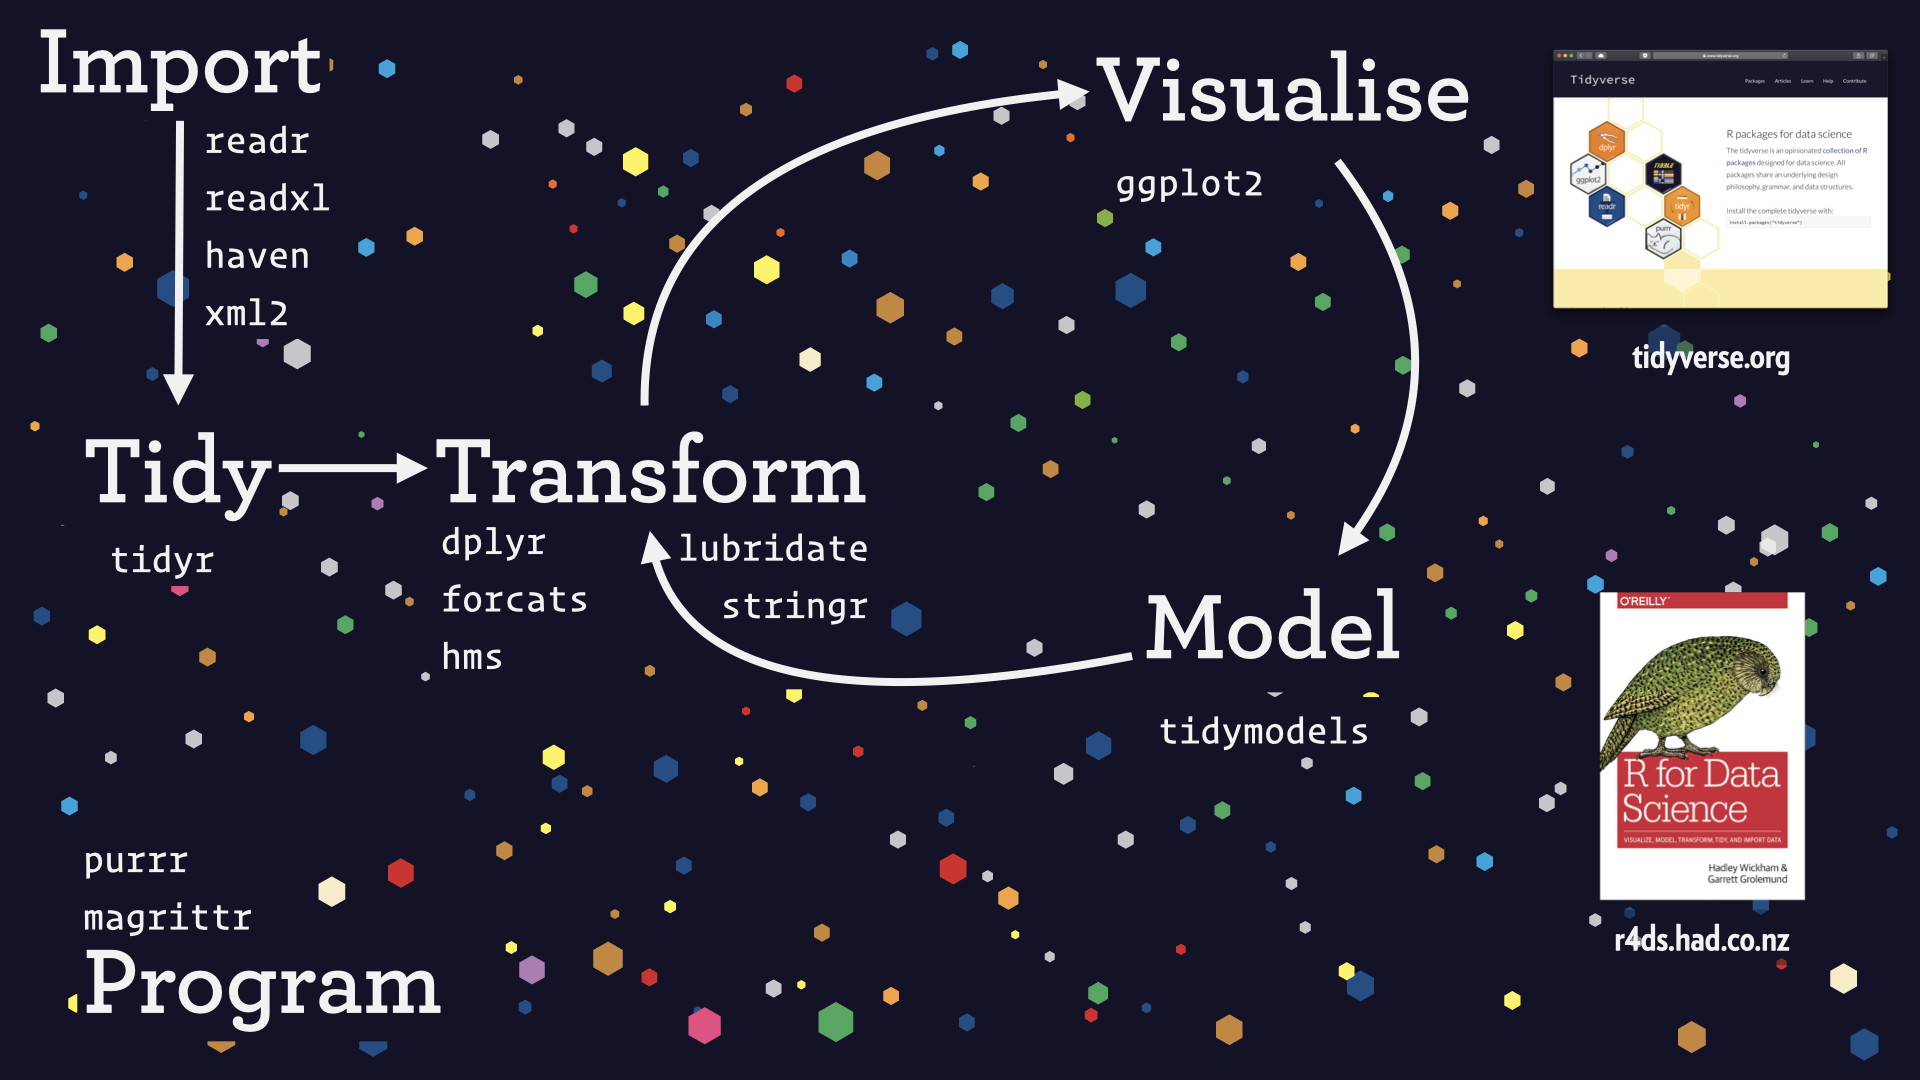
<figcaption>Figure 2: The packages of the tidyverse, organised using a partial version of my model of the data science workflow. The missing step is communication, which is aided by tools outside the tidyverse, like Quarto and Shiny. This image comes from a presentation called the “Joy of Data Science” which I gave in 2020.</figcaption>
</figure>

### Defining the tidyverse

Naming the tidyverse created some bigger questions: What exactly is the tidyverse? What are the unifying principles that underlie the packages in the tidyverse? In my useR talk I cited three unifying principles:

-   Uniform data structures.
-   Uniform APIs.
-   Support referential transparency.

I think the first two principles are straightforward: it’s easier to learn a new tool if it uses data structures and interfaces that you’re already familiar with. But what does it mean to support referential transparency? That’s a call to the principles of tidy evaluation, which we’ll come back to in <a href="#sec-tidy-eval" class="quarto-xref">Section 4.4</a>.

I repeated my introduction to the tidyverse talk a few times that year and by December 2016 I’d further refined the core principles to these four:

-   Share data structures (i.e. tidy tibbles).
-   Compose simple pieces (i.e. use the pipe).
-   Embrace functional programming (instead of for loops).
-   Write for humans.

The final bullet was particularly motivated by this quote:

> Programs must be written for people to read, and only incidentally for machines to execute.  
> — Hal Abelson

I think that’s a particularly important principle for data science code, because it’s very important to be able to read, understand, and the critique the code used to perform an analysis. Ideally, you’re not just solving a problem with code, you’re also documenting how you solved it so that you (and others) can understand the path that you’ve taken.

Since that time I’ve continued the definition of the tidyverse and you can see my latest iteration in [Tidy design principles](https://design.tidyverse.org/unifying.html). At the time of writing, the four principles of the tidyverse were:

-   It is **human centred**, i.e. the tidyverse is designed specifically to support the activities of a human data analyst.

-   It is **consistent**, so that what you learn about one function or package can be applied to another, and the number of special cases that you need to remember is as small as possible.

-   It is **composable**, allowing you to solve complex problems by breaking them down into small pieces, supporting a rapid cycle of exploratory iteration to find the best solution.

-   It is **inclusive**, because the tidyverse is not just the collection of packages, but it is also the community of people who use them.

### Learning

Once I had identified the tidyverse, it become natural to ask “how do you learn it?” The answer to this question became the book [R for Data Science](https://r4ds.hadley.nz) ([Wickham and Grolemund 2017](#ref-r4ds-1); [Wickham, Çetinkaya-Rundel, and Grolemund 2023](#ref-r4ds-2)). I wrote a book because I believe that books are one of the best ways to spread big ideas; the linear format allows you to lead the reader step-by-step and you have plenty of space to go in to the details. Equally important to me was that the book should be available to all, regardless of their ability to pay. That’s why all the books I write have a dual production model: a free HTML version that I produce and a paid physical version produced by a commercial publisher.

R for Data Science proved to be extremely popular. It sold very well, but more importantly to me, a ton of people used the website[4]. One of my favourite things about the book is how many languages it has been translated into including Russian, Polish, Japanese, Chinese (traditional) and Chinese (simplified). I’m particularly fond of the community translations ([Spanish](http://es.r4ds.hadley.nz/), [Italian](https://it.r4ds.hadley.nz/), [Turkish](https://tr.r4ds.hadley.nz/), and [Portuguese](https://pt.r4ds.hadley.nz/)) because they were translated by volunteers and made freely available to the world.

## Key innovations

So far I’ve traced the chronological development of the tidyverse, but I also want to examine some of the specific innovations that emerged during this journey. These innovations weren’t just programming achievements: they represent new ways of thinking about and interacting with data, and helped to build a community around the tidyverse. I’ve selected five contributions—tidy data, tibbles, the pipe, tidy evaluation, and hex stickers—that I’m particularly proud of. Let’s examine each of these key developments in turn.

### Tidy data

I’ve always had a very strong sense that there’s a “right” way to organise your data, a way that would make the rest of your analysis much easier. And when looking at a dataset I could usually identify what form would be the most productive. But I had a time explaining what I was doing to others, and experienced numerous failures when trying to teach my approach to students. Eventually I figured out the three principles of tidy data[5] and elucidated them in Wickham ([2014](#ref-tidy-data)):

-   Each variable goes in a column.
-   Each observation goes in a row.
-   Each value goes in a cell.

This definition seems to work for people from diverse academic backgrounds, even without a precise definition of variable and observation. Given their simplicity, it seems hard to understand why it took me so long to figure them out. It’s also a strange gap in the statistics literature: this is one of the very few papers that actually describe how you should structure your data in order to do statistics.

[1] e.g. <https://github.com/imanuelcostigan/hadleyverse>

[2] In June 2016, Winston Chang and I brainstormed a bunch of ideas in slack: shipshape, trim, spruce, dapper, natty, joy-sparking, spiffy, choice, debonair, suave, virile, civil, gallant, pulchritudinous, graceful, well-tempered, deft, fastidious, slick, crack, mellow, mannerly, unctuous, tolerable, glib, fluent, affable, agreeable, stout, dashing, snazzy, boffo, raffish, rakish, swashbuckling, nifty, phat, dandy, sleek.

[3] We had wanted to add lubridate along with forcats and stringr, but there were a couple of function names that caused conflicts. The process of eliminating these functions without unduly affecting user code took a further five years.

[4] According to my web statistics, around 1 million unique visitors and 2.9 million page views in the last year.

[5] This is certainly not the only data stucture you might ever want to use, but it’s extremely useful to have a organising structure that you can rely on for the majority of your work. It’s a great default, even if you might need other forms for specialised purposes.

The definition of tidy data was tightly paired with [tidyr](https://tidyr.tidyverse.org)[1], a package that helps tidy your data. This package initially provided the `gather()` and `spread()` functions, but many people (including me!) had a hard time remembering which was which and how their arguments worked. Additionally, their design wasn’t quite flexible enough to handle all the problems which we later discovered in practice. In [tidyr 1.0.0](https://www.tidyverse.org/blog/2019/09/tidyr-1-0-0/) (2019), we resolved many of these problems by introducing the new `pivot_longer()` and `pivot_wider()` functions. These new names were informed by (casual) user research, where I asked my twitter followers to describe two data transformation operations. You can learn more about this research at <https://github.com/hadley/table-shapes>.

tidyr 1.0.0 also expanded the scope of the package to encompass “rectangling”, a new term for converting hierarchical data into tidy rectangles. At the time, this was becoming increasingly important as more data was coming from JSON web APIs, which tended to produce deeply nested data structures. You can learn more about the problem and the solutions that tidyr provides in [tidyr’s rectangling vignette](https://tidyr.tidyverse.org/articles/rectangle.html).

[1] Fun fact: I only realised that tidyr was an anagram of dirty when someone pointed it out on twitter several years later.

### tibbles

Tidy data provides a theoretical framework to productively organise your data. But you also need a practical data structure where this data can live. Base R provides the data frame, but I found that it suffered from a number of small issues that added needless friction. To resolve these issues, I created the tibble, an extension of the data frame with a number of small changes:

-   Data frames can flood your console with output when working with datasets containing many rows or many columns. In older versions of R, you couldn’t even cancel this display, making it easy to lock yourself out of your console when working with bigger datasets. tibbles print only a small number of rows and just the columns that fit on one screen. You can always explicitly request more data, but the defaults keep your analysis workflow nimble.

-   When teaching, I found that students didn’t have a good sense for column types, and even I sometimes found myself confused about whether a column was a date, a string, or factor. To avoid this problem, tibbles show (abbreviated) variable types underneath the column names.

-   In the unfortunate case of `data.frame(x = c(NA, "<NA>"))`, there’s no way to distinguish the two values from the printed output. Tibbles use a side-channel, colour, to ensure that there’s no way to confuse a missing value and a string with the same printed representation.

-   Base data frames technically support nested data structures, like columns that are themselves data frames or columns that are lists of data frames. But they are printed poorly, making them hard to use. Tibbles strive to represent these more complex data types in a readable way, making them more usable where needed.

tibbles also resolve a couple of subsetting gotchas that make it easy to make silent errors when writing package code. For example, if `df` is a data.frame, then:

-   `df[, cols]` can return either a vector or a data frame, depending on the contents of `col`.

-   `df$x` uses partial matching, so that if column `x`doesn’t exist but column `xyz` does, it will silently return `df$xyz`.

If `df` is a tibble then neither of these problems occur because `df[]` always returns another tibble and `df$x` never performs partial matching. This is why I have jokingly described tibbles as lazy and surly versions of data frames.

tibbles started life in dplyr, originally called `tbl_df`s with no suggestion as how to pronounce their name. [Kevin Ushey](https://x.com/kevin_ushey/status/514659005621219329) proposed pronouncing them as tibble-diffs in 2014, and the tibble bit stuck. As the utility and complexity of tibbles expanded, they needed more space to grow and were [extracted into their own package](https://posit.co/blog/tibble-1-0-0/) in 2016.

tibbles were a much more contentious data structure than I had anticipated. They broke code in older packages and my strong opinions about the formatting of significant digits caused some community consternation. The contention seems to have mostly died down, but today I am much more cautious about introducing new data structures. New data structures are fundamentally much more costly than new functions or packages, and they need to be kept to the bare minimum.

### The pipe

> No matter how complex and polished the individual operations are, it is often the quality of the glue that most directly determines the power of the system.
>
> — Hal Abelson

The pipe quickly became one of the defining features of tidyverse code. It allows you to rewrite function composition (e.g. `f(g(x)))`) as a linear sequence of transformations (e.g. `x |> g() |> f()`), which tends to make common data analysis programming patterns much easier to read.

I first implemented the pipe in dplyr in Oct 2013 and called it `%.%`. When [I announced dplyr](https://rstudioblog.wordpress.com/2014/01/17/introducing-dplyr/) in January 2014, I learned that Stefan Milton Bache had been thinking along similar lines and had created the magrittr package. It used `%>%` instead of `%.%`, which is easier to type (since you can hold down the shift button the whole time[1]), and had more comprehensive features. So I quickly pivoted to use magrittr and deprecated `%.%`. I was initially cautious about this new syntax, but users picked up on it quickly, and I found it easy to teach. You can learn more about the early history of the pipe in Adolfo Álvarez’s excellent blog post “[Plumbers, chains, and famous painters: The (updated) history of the pipe operator in R](http://adolfoalvarez.cl/blog/2021-09-16-plumbers-chains-and-famous-painters-the-history-of-the-pipe-operator-in-r/)”.

Today, the pipe is available in base R thanks to a collaborative effort. In 2016, Lionel Henry [proposed new syntax](https://lionelhenry.github.io/2016/02/15/ideas-for-an-updated-r-syntax/index.html) and wrote a patch for R, which Jim Hester presented to the R Core Team at the Directions in Statistical Computing Conference in 2017. This presentation was received positively, but it took some time for R Core to fully align on the utility of the pipe. Three years later, Luke Tierney added the base pipe to R 4.1 (2020), following up with placeholder syntax in R 4.2, and support for `$`, `[` and `[[` in R 4.3. Because R can modify the parser, the base pipe has better syntax, `|>`, including a more visible placeholder, `_`. With the maturity of the base pipe, the tidyverse is gradually moving away from `%>%` towards `|>`, a process that will take several years to complete.

As an interesting historical anecdote, there would have been no need for ggplot2 had I discovered the pipe earlier, as ggplot was based on function composition. I correctly identified that function composition was an unappealing user interface, but if I had discovered the pipe at that time, ggplot could have used it, rather than needing to switch to `+` in ggplot2. You can [try out ggplot](https://github.com/hadley/ggplot1) if you want, or [learn why ggplot2 can’t switch to the pipe](https://forum.posit.co/t/why-cant-ggplot2-use/4372).

### Tidy evaluation

One of the most challenging features of the tidyverse is tidy evaluation. It’s hard to briefly define tidy evaluation, but fortunately it’s straightforward to motivate with an example. Imagine you’ve written the following repeated code, and following the “rule of three”, you want to extract out the repetition into a function:

[1] The requirement for infix function names to start and end with `%` comes from R, and there’s no avoiding it without patching R itself.

In [ ]:
df1 |>
  group_by(g1) |>
  summarise(mean = mean(a))
df2 |>
  group_by(g2) |>
  summarise(mean = mean(b))
df3 |>
  group_by(g3) |>
  summarise(mean = mean(c))

You might try the usual approach to writing a function and come up with the following code:

In [ ]:
library(dplyr)
df1 <- data.frame(g1 = 1, a = 2)

In [ ]:
grouped_mean <- function(df, group_var, summary_var) {
  df |>
    group_by(group_var) |>
    summarise(mean = mean(summary_var))
}

df1 |> grouped_mean(g1, a)
#> Error in `group_by()`:
#> ! Must group by variables found in `.data`.
#> ✖ Column `group_var` is not found.

This code doesn’t work because dplyr looks for a variable literally named `group_var`, not the variable, `a`, that you want. I think we now know how to succinctly define the problem: we use the word variable to mean two different things. A **data-variable** is a statistical variable, something that exists inside a data frame, like `g1`, or `a`. An **environment-variable** is a computer science variable, something that exists in (e.g.) the global environment, like `df1` or `df2`. The fundamental challenge of tidy evaluation is handling the case where you have a data-variable (e.g. `g1`) stored inside of a environment-variable (e.g. `group_var`).

It took us around five years to provide the tools to fully solve the problem. My efforts started in dplyr 0.3.0 (2014) with the introduction of the [lazyeval](https://cran.r-project.org/web/packages/lazyeval) package. There were three pieces:

-   `lazyeval::lazy()` allowed you to capture the data-variable stored inside an environment-variable, producing an explicit lazy object.
-   `lazyeval::interp()` allowed you to interpolate a lazy object into a bigger expression creating a new lazy object.
-   Every dplyr function had a variant that ended in an underscore that took lazy objects.

That led to a solution that looks like this:

In [ ]:
grouped_mean <- function(df, group_var, summary_var) {
  group_var <- lazyeval::lazy(group_var)
  summary_var <- lazyeval::lazy(summary_var)

  df |>
    group_by_(group_var) |>
    summarise_(mean = lazyeval::interp(~ mean(summary_var), summary_var))
}

This approach worked, but was a bit clunky. Additionally, in July 2016, I learned that the technique that allowed `lazy()` to work would be no longer supported in a future version of R, which lead me back to the drawing board. Fortunately Lionel Henry had recently joined my team and had a bunch of ideas of how to improve the situation. That lead us to a new framework called tidy evaluation (tidyeval for short) which we introduced to dplyr 0.6.0 (2017).

Tidy evaluation is provided by the [rlang](https://rlang.r-lib.org/) package, and introduces two new tools:

-   `enquo()` lets you to “quote” an environment-variable creating an explicit quosure object.

-   `!!` (pronounced bang-bang), allowed you to “unquote” or interpolate a quosure into a bigger expression.

This approach was appealing because every dplyr function could itself call `enquo()`, meaning that we no longer needed to have two versions of every function. This led to the following solution:

In [ ]:
grouped_mean <- function(df, group_var, summary_var) {
  df |>
    group_by(!!enquo(group_var)) |>
    summarise(mean = mean(!!enquo(summary_var)))
}

Tidy evaluation included a solid theoretical foundation, making us more confident that our implementation was correct and complete. I still believe that theory is really important but experience taught us that few R users wanted to learn it. During 2017 and 2018 I gave 12 talks on tidyeval around the world, trying to convince others that they could use tidyeval for their own code. But this was much less effective than I had hoped and there were general rumblings in the community that tidyeval was too hard[1].

This again sent us back to the drawing board and we came up with a new approach called embracing [in mid 2019](https://www.tidyverse.org/blog/2019/06/rlang-0-4-0). This style introduced just one new operator `{ }`, which you use whenever you have an data-variable referenced by an environment-variable. While `enquo()` and `!!` continue to be used behind the scenes, there’s now only one bit of new syntax to learn. This leads to a simple implementation of `grouped_mean()`:

[1] Memorable examples of this included posts on the RStudio community forum titled “Should tidyeval be abandoned?” and “Will tidyeval kill the tidyverse?”.

In [ ]:
grouped_mean <- function(df, group_var, summary_var) {
  df |>
    group_by({{ group_var }}) |>
    summarise(mean = mean({{ summary_var }}))
}

We had also missed a few of common problems that were surprisingly hard to solve with existing tools, which required a few smaller enhancements and some better documentation. Now we have a [cookbook](https://dplyr.tidyverse.org/articles/programming.html) that doesn’t require any theoretical knowledge and the grumblings about tidyeval seem to have subsided.

### Hex logos

You can’t talk about the history of the tidyverse without also talking about hex logos. While the early history of hex logos is now murky, from what I can tell, it appears that Stefan Milton Bache and I co-discovered hex stickers around the same time in 2014[1] through <https://hexb.in>. I personally found it very appealing to have a shape that can tile the back of a laptop, along with a spec that ensures everyone’s stickers are the same size and the same orientation (point down!).

I’m pretty sure the first hex logo was magrittr’s[2], designed by Stefan in December 2014. Soon afterwards I fully I embraced the idea of hex stickers and started creating them for key packages with the help of designer Greg Swinehart; you can see two early versions of the ggplot2 logo in <a href="#fig-early-logos" class="quarto-xref">Figure 3</a>. By mid-2016 we were ordering them en masse for RStudio events, and we were beginning to see logos for other packages in the community.

<figure id="fig-early-logos">
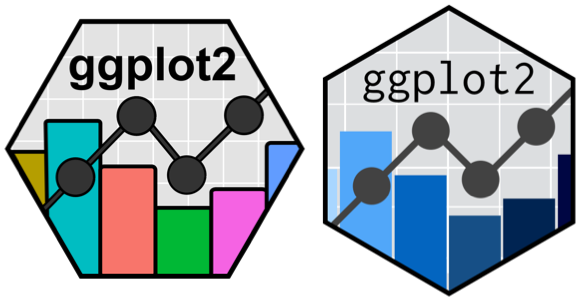
<figcaption>Figure 3: Two early versions of the ggplot2 hex logo. I can’t find any record of who created the first version (left), but I presume it was me given the incorrect orientation of the hex. The second version (right) was created in concert with Garrett Grolemund.</figcaption>
</figure>

Today, a huge number of packages have a logo, and I love seeing the creativity and diversity package authors bring to their design! I love hex stickers as a community building tool: people can see your laptop, immediately recognise you as a member of the R community, and get a sense of what you use R for. I’ve heard many stories of people striking up a conversation with strangers just because they recognised the stickers. They also play a role akin to trading cards and <a href="#fig-hex-office" class="quarto-xref">Figure 4</a> shows a collection of stickers that I’ve been given over the years.

<figure id="fig-hex-office">
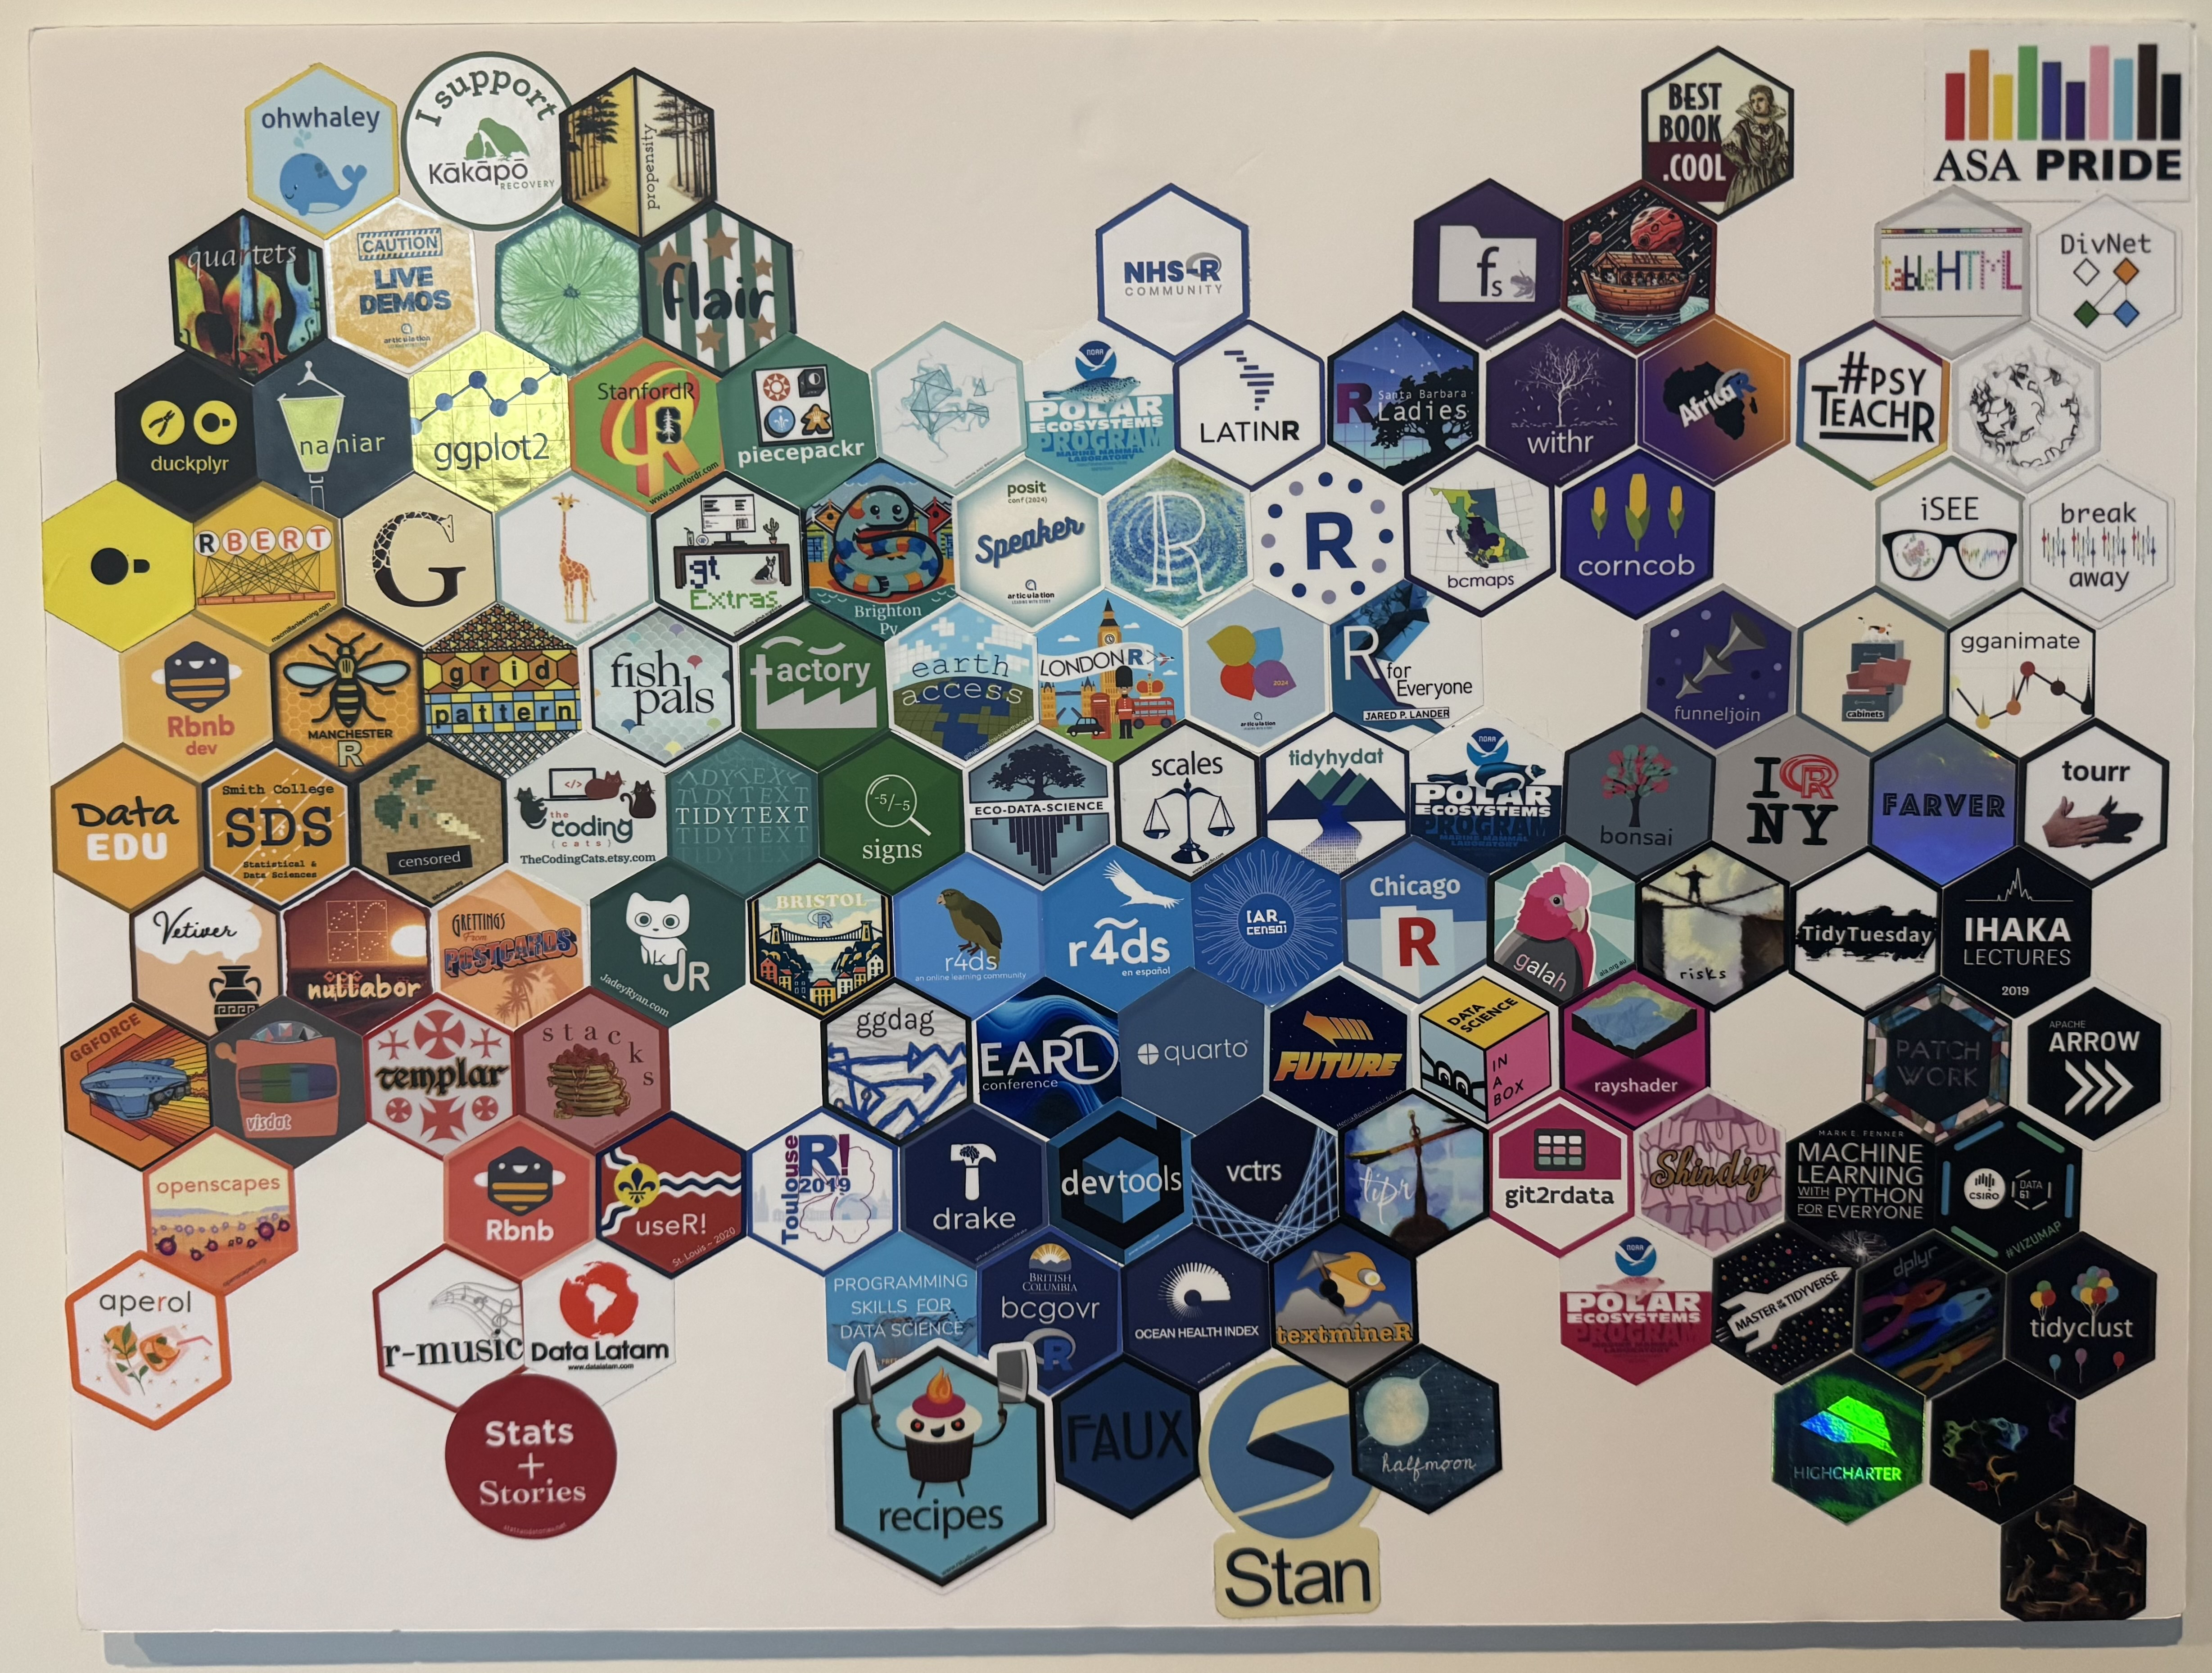
<figcaption>Figure 4: A board of hex stickers on display in my office.</figcaption>
</figure>

[1] Stefan and I were clearly thinking many of the same thoughts in 2014!

[2] <https://github.com/max-mapper/hexbin/commits/gh-pages/hexagons/magrittr.png>

## The tidyverse at Posit

The naming of the tidyverse coincided with the start of my team at RStudio (now Posit), and the overarching journey from a project that was primarily developed by me to one with many full-time contributors. This wouldn’t have been possible without Posit, which has funded this work as part of its public benefit corporation mission. I feel tremendously lucky to work at an organisation who’s mission so closely aligns with my own.

The tidyverse team currently includes Lionel Henry, Jenny Bryan, Gábor Csárdi, Mine Çetinkaya-Rundel, Thomas Lin Pedersen, Davis Vaughan, George Stagg, and Teun Van den Brand, as well as the tidymodels team, described below. Jim Hester, Mara Averick, Romain Francois, Tracy Teal, and Andy Teucher have moved on from their full-time roles at Posit but many of remain active in the community and they’re all still valued members of the broader “team tidyverse”.

The mission of the team is broad and extends well beyond the tidyverse: we want to make R the best environment for doing data science. We have nothing against other programming languages (and certainly use them where appropriate), but we love R, believe in it, and believe that you have to stay focused if you want to have an impact.

To achieve this mission the most obvious skills we deploy are our programming skills: we write a lot of R code (as well as a smattering of C, C++, Rust, and Javascript) to create packages. Our mission extends beyond just tidyverse packages because we recognise that few analyses can be completed with the tidyverse alone, and most will require additional special purpose tools. For this reason, we strive to help every R package developer make higher quality packages. You can see this work in books like [Advanced R](https://adv-r.hadley.nz) and [R Packages](https://r-pkgs.org) and in the devtools family of packages that support tasks related to package development. This family of packages has had a big impact on the practice of package development: at the time of writing, ~9,000 packages use testthat for unit testing, ~12,000 packages use pkgdown to make package websites, and ~16,000 packages use roxygen2 to generate documentation.

But it doesn’t matter how useful your code is if no one knows about it. So we believe that marketing and education are as important as programming, and all team members are expected to contribute to our outreach by [writing blog posts](https://www.tidyverse.org/blog), writing books, giving talks, teaching workshops, and generally helping to build and support the R community. We’re also a generally process-oriented team and we do our best to write up our processes so that others can benefit from them. This work includes:

-   Our package release checklist (created by `usethis::use_release_isse()`) ensures that we maximise the chances of successful CRAN submission by following a standard process. Our process grows as we discover new problems, and shrinks as we figure out how to automate manual steps away.

-   We strive to keep our code formatting as consistent as possible so we wrote up our choices in the [tidyverse style guide](https://style.tidyverse.org). This is probably the most commonly used style guide in the R community.

-   We spend a lot of time reviewing code (both internally and externally) so we wrote up [code review guidelines](https://code-review.tidyverse.org) to keep our own work consistent, and to help new contributors know what to expect. This work was lead by Davis Vaughan.

-   We are slowly working on an exposition of the [design principles](https://design.tidyverse.org) that guide the design of tidyverse APIs. This is helpful for us, because it makes it easier to remember design decisions and re-apply them the same way in multiple places, and also helps the community see reusable patterns that they can apply to their own code.

Our broad mission means that recently we have been spending less time on tidyverse packages and more time on broader data science efforts; I’ll come back to our current areas of focus at the end of this paper.

### tidymodels

Within the tidyverse team, the tidymodels team has a narrower mission: improving the tools data scientists need to do statistical modelling and machine learning. The tidymodels team started in late 2016 when Max Kuhn joined RStudio, after initial talks about how we could support statistical and ML modelling. As well as Max, the tidymodels team currently consists of Hannah Frick, Simon Couch, and Emil Hvitfeldt.

Max was the obvious choice to found this team because of his work on the caret package. caret provided functionality for basic predictive modelling tasks such as performance measures and resampling as well as a consistent user interface across many modelling packages. Based on this work, Max wanted to create a more extensible framework that would integrate more advanced tools, such as more complex pre- and post-processing, and censored regression models. The resulting collection of packages was called tidymodels and heavily relied on the tidyverse syntax and the underlying tools described above.

A defining feature of tidymodels is its lighthearted approach to naming and the fun it has with package logos. For example, for a package similar in spirit to caret, Max’s initial idea was to give it the code name “carrot” to confuse outside users. I proposed “parsnip”, and the name stuck.

## Tidyverse community

The tidyverse transcends its technical foundations to represent something far greater: a vibrant, global community of practitioners, educators, and users who have embraced these tools to solve real-world problems. While the core team at Posit provides stewardship and a core of software development expertise, the true strength of the tidyverse flows from its diverse community of users and contributors.

What makes the tidyverse community special is not just its size or reach, but its culture of mutual support and shared learning. Whether someone is taking their first steps with R or pushing the boundaries of what’s possible with these tools, they’ll find a community ready to help them succeed. This collaborative spirit has created a virtuous cycle where learning flows in all directions: new users bring fresh perspectives and questions that challenge assumptions, while experienced practitioners share deep insights that push the ecosystem forward.

For us working on the tidyverse, the community serves as both motivation and guide. Your successes energise us, your challenges direct our efforts, and your creativity constantly expands our vision of what’s possible. This section explores the various dimensions of this community – from its evolution across different social platforms to the crucial role of community contributors in shaping and improving the tidyverse itself.

### Social media and community spaces

The early R community centred around traditional mailing lists, particularly r-help and r-devel. While these lists were invaluable for early R users, they reflected the academic statistical computing culture of the time – technically rigorous, but often unwelcoming to newcomers[1]. This environment prompted the creation of alternative spaces, including the ggplot2 mailing list in 2008, which explicitly aimed to provide a more supportive environment for users learning data visualisation.

But the real transformation began with the community’s migration to more modern platforms. Stack Overflow emerged as a crucial resource for asking and answering coding questions, and, despite some toxicity amongst the self-appointed moderators, was generally a welcoming environment. Twitter was particularly transformative in 2010-2022. The #rstats hashtag created a space where users could share quick tips, celebrate successes, and build personal connections. The R community on Twitter became known for its supportive and welcoming atmosphere, standing in marked contrast to the less friendly environs found in other technical communities. I believe a big part of this is due the diversity of R users, which has been tremendously boosted thanks to groups like [R-Ladies](https://rladies.org), [Minorities in R](https://mircommunity.com), and [rainbowR](https://rainbowr.org).

Today, the R community has mostly shifted to new platforms like Mastodon, LinkedIn, and Bluesky. I find Bluesky particularly rewarding; while the platform is still evolving, it has already become a vibrant hub for maintaining the connections that make the R community special.

### Community contributors

The tidyverse wouldn’t be a fraction as good as it is today without community contributions. To foster this collaborative spirit, we actively encourage and celebrate contributions of all sizes, from minor bug fixes to major feature enhancements. A key tool in supporting our community of developers are the Tidyverse Developer Days, which we launched in [2019](https://www.tidyverse.org/blog/2019/04/tidyverse-dev-day-at-user-2019/). These hands-on events provide a welcoming environment where participants learn the ins and outs of contributing to the tidyverse while tackling real issues with a ton of hands on support. While the COVID-19 pandemic paused these gatherings after [2020](https://www.tidyverse.org/blog/2020/02/tidy-dev-days-2020/), we’ve reinstated them in [2024](https://www.tidyverse.org/blog/2024/04/tdd-2024/) and plan to make them an annual event following each posit::conf.

Most external contributors tend to provide a few small (but meaningful!) contributions. A limited number of external contributors end up contributing much time and effort over the course of many years. We recognise these contributors by making them package authors. This formally includes them in package metadata (so they are explicitly acknowledged on CRAN, on the package website, and in the package citation) and gives them write access to the GitHub repository. You can learn more about the rights and responsibilities of authors (and other roles) in our [tidyverse governance model](https://github.com/tidyverse/tidyups/blob/main/004-governance.md).

Many package authors are academics, and since the currency of academics is citations, in 2019 we made the effort to write Wickham et al. ([2019](#ref-tidyverse-welcome)). This makes it easy to cite the tidyverse as a whole[2] and gives academic credit to tidyverse maintainers who might benefit from it. In alphabetical better, the authors are: Mara Averick, Jennifer Bryan, Winston Chang, Lucy McGowan, Romain François, Garrett Grolemund, Alex Hayes, Lionel Henry, Jim Hester, Max Kuhn, Thomas Pedersen, Evan Miller, Stephan Bache, Kirill Müller, Jeroen Ooms, David Robinson, Dana Seidel, Vitalie Spinu, Kohske Takahashi, Davis Vaughan, Claus Wilke, Kara Woo, and Hiroaki Yutani. This paper has been cited over 16,000 times at time of writing.

Since we’ve published that paper we’ve gained a few new maintainers such as Maximilian Girlich (tidyr, dbplyr), Mark Fairbanks (dtplyr), Ryan Dickerson (dtplyr), Olivier Roy (pkgdown), Danny Smith (haven), Maxim Shemanarev (ragg), and Teun van den Brand (ggplot2).

## Maintaining the tidyverse

For the last few years, the tidyverse has felt pretty mature to me. It’s certainly not perfect, but it feels like we have all of the main pieces in place, and much of the remaining work is grinding down the minor inconsistencies between them. Overall, the goal of the tidyverse is now consolidation and maintenance, not growth.

To support this goal, we worked on three major projects:

-   In 2019, we created a policy for [R version support](https://www.tidyverse.org/blog/2019/04/r-version-support/) (the current version, the development version, and the previous four versions). Coupled with R’s yearly release cycle, this means we support 5 years of R versions. This policy is important because many large enterprises use older versions of R, but still want to be able to use the latest and greatest package versions.

-   In 2020 and early 2021, we defined a [lifecycle policy](https://www.tidyverse.org/blog/2021/02/lifecycle-1-0-0/). The early days of the tidyverse were characterised by rapid evolution and backward incompatible change. This allowed us to rapidly evolve towards better user interfaces, but we the community found that the pace of change was too high. The lifecycle policy helps us clearly communicate the state of different functions and provides a clear commitment to backward compatibility.

-   In late 2021, we [re-licensed most tidyverse packages](https://www.tidyverse.org/blog/2021/12/relicensing-packages/) to the MIT license. This increased consistency across packages, making it easier for legally conservative organisations to convince themselves there was little risk to using the tidyverse.

There is one more maintainability change that I hope to make in the future: **editions**. The idea of an edition is that you can run code like `tidyverse::edition(2025)` to opt-in to our best practices as of (e.g.) 2025. Editions allows us to steer you towards the APIs that we think are best and make it possible to change sub-optimal behaviour without breaking existing code. For example, we could use editions to change the default colour schemes in ggplot2. We know that these could be improved, but we can’t change the defaults without breaking a lot of existing plots.

## What’s next?

As the tidyverse becomes more mature, the places where the tidyverse team spends our innovation energy have started to change. Our mission is broad and we’re willing to go wherever this takes us, even if it’s into new areas that we know little about. Currently there are three new areas that we are exploring as a team:

-   **Positron**. [Positron](https://github.com/posit-dev/positron) is a new IDE for data science, produced by the same team that created RStudio. The tidyverse team has been deeply involved in Positron’s tooling for R. This is exciting because it gives us new skills, allowing us to create coding interfaces where that makes the most sense, and to create graphical user interface where that is a better fit.

-   **R in production**. If you’re working in industry, most analyses aren’t completed by writing a one-off report. Instead, you will typically produce a living artefact that’s run repeatedly over months or years. This is the challenge of putting your code in production, which currently feels harder than it should be, due to a large number of paper cuts. These include tasks like getting database authentication working when your code is deployed on a server that distracts from your data science tasks. In conjunction with other teams at Posit, I’m convinced we can make many of these problems go away.

-   **LLMs for data science**. By now, it’s clear that LLMs are going to have a transformative impact on how we do data science. We see them as invaluable assistants for the data scientist, not replacements, tools that allow you to get help where you need it and automate fiddly annoying tasks. Our work in this domain is still very early, but one initiative is the [ellmer package](https://ellmer.tidyverse.org) which lets you use LLMs from a variety of providers within R.

It’s been a lot of fun to look back at the last ~20 years of the tidyverse. What started as a collection of personal solutions to data analysis challenges has grown into something far greater than I could have imagined – a vibrant ecosystem that helps millions of people around the world work more effectively with their data. Our amazing community continues to inspire me daily with their creativity, generosity, and enthusiasm.

Looking ahead, I’m more excited than ever about the future of R and the tidyverse. The emergence of new technologies like LLMs offers fresh opportunities to make data science more accessible and more usable. While the core tidyverse packages may be reaching maturity, there are still countless opportunities to reduce friction, improve consistency, and help people solve real-world problems more effectively.

I still love R, love programming, and most importantly, love working with this incredible community. Here’s to the next 20 years of making data science more approachable, more powerful, and more fun!

Grolemund, Garrett, and Hadley Wickham. 2011. “Dates and Times Made Easy with <span class="nocase">lubridate</span>.” *Journal of Statistical Software* 40 (3): 1–25. <https://www.jstatsoft.org/v40/i03/>.

Sarkar, Deepayan. 2008. *Lattice: Multivariate Data Visualization with r*. New York: Springer. <http://lmdvr.r-forge.r-project.org>.

Wickham, Hadley. 2014. “Tidy Data.” *Journal of Statistical Software* 59 (10): 1–23. <https://doi.org/10.18637/jss.v059.i10>.

Wickham, Hadley, Mara Averick, Jennifer Bryan, Winston Chang, Lucy D’Agostino McGowan, Romain François, Garrett Grolemund, et al. 2019. “Welcome to the Tidyverse.” *Journal of Open Source Software* 4 (43): 1686. <https://doi.org/10.21105/joss.01686>.

Wickham, Hadley, Mine Çetinkaya-Rundel, and Garrett Grolemund. 2023. *R for Data Science*. " O’Reilly Media, Inc.".

Wickham, Hadley, and Garrett Grolemund. 2017. *R for Data Science*. " O’Reilly Media, Inc.".

Wilkinson, Leland. 2012. *The Grammar of Graphics*. Springer.

[1] I still remember a conversation where I was told to look up a word in the dictionary.

[2] We include some advice on citing packages in our blog post advertising the paper: <https://www.tidyverse.org/blog/2019/11/tidyverse-1-3-0/>.